## List files and types

To understand what files have been loaded

In [1]:
from pathlib import Path
from collections import Counter

root = Path("/kaggle/input")
files = sorted(p for p in root.rglob("*") if p.is_file())

print(f"Total files: {len(files):,}")
print(f"Total size: {sum(p.stat().st_size for p in files) / 1024**3:.2f} GiB")

extensions = Counter(p.suffix.lower() or "[no extension]" for p in files)

print("\nFile types:")
for extension, count in extensions.most_common():
    print(f"{extension:15} {count:,}")

print("\nFirst 40 file paths:")
for path in files[:40]:
    print(path.relative_to(root))

print("\nVideo, annotation, and archive examples:")
relevant = [
    p for p in files
    if p.suffix.lower() in {
        ".mp4", ".avi", ".json", ".csv", ".txt",
        ".tar", ".gz", ".zip"
    }
]
for path in relevant[:30]:
    print(path.relative_to(root))

Total files: 120
Total size: 3.07 GiB

File types:
.png            36
.npy            36
.mp4            24
.json           12
.txt            12

First 40 file paths:
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/background.png
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/background_depth.png
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/color.mp4
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/depth.mp4
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/depth_scale.npy
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/inverse_intrinsic.npy
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/mask.png
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/output.json
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/rot.npy
datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002/times.txt

12 clip folders, each with videos, annotations, timestamps, and supporting files

## Inspection of annotations

Goal - To understand how labels are stored


In [2]:
# Annotation Inspection

import json

annotation_path = sorted(root.rglob("output.json"))[0]

with annotation_path.open() as f:
    annotation = json.load(f)

print("Selected clip:", annotation_path.parent)
print("\nTop-level keys:", list(annotation.keys()))

objects = annotation.get("objects", [])
print("\nNumber of annotated tracks:", len(objects))

if objects:
    first_pig = objects[0]

    print("\nFirst track keys:", list(first_pig.keys()))
    print("Pig tracking ID:", first_pig.get("id"))

    entries = first_pig.get("frames", [])
    print("Stored annotation entries for this track:", len(entries))

    print("\nFirst 3 annotation entries:")
    print(json.dumps(entries[:3], indent=2))

Selected clip: /kaggle/input/datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002

Top-level keys: ['videoFileName', 'fullVideoFilePath', 'stepSize', 'config', 'objects']

Number of annotated tracks: 8

First track keys: ['frames', 'id']
Pig tracking ID: 3
Stored annotation entries for this track: 507

First 3 annotation entries:
[
  {
    "frameNumber": 0,
    "bbox": {
      "x": 196,
      "y": 299,
      "width": 240,
      "height": 121
    },
    "isGroundTruth": true,
    "visible": true,
    "behaviour": "investigating"
  },
  {
    "frameNumber": 1,
    "bbox": {
      "x": 196,
      "y": 290,
      "width": 261,
      "height": 122
    },
    "isGroundTruth": true,
    "visible": true,
    "behaviour": "investigating"
  },
  {
    "frameNumber": 2,
    "bbox": {
      "x": 196,
      "y": 283,
      "width": 251,
      "height": 190
    },
    "isGroundTruth": true,
    "visible": true,
    "behaviour": "investigating"
  }
]


Labels are organized by pig track, with frame references, boxes and behaviors

## Display annotated frame

- Drew boxes and labels over the image where we are checking coordinates and correct image

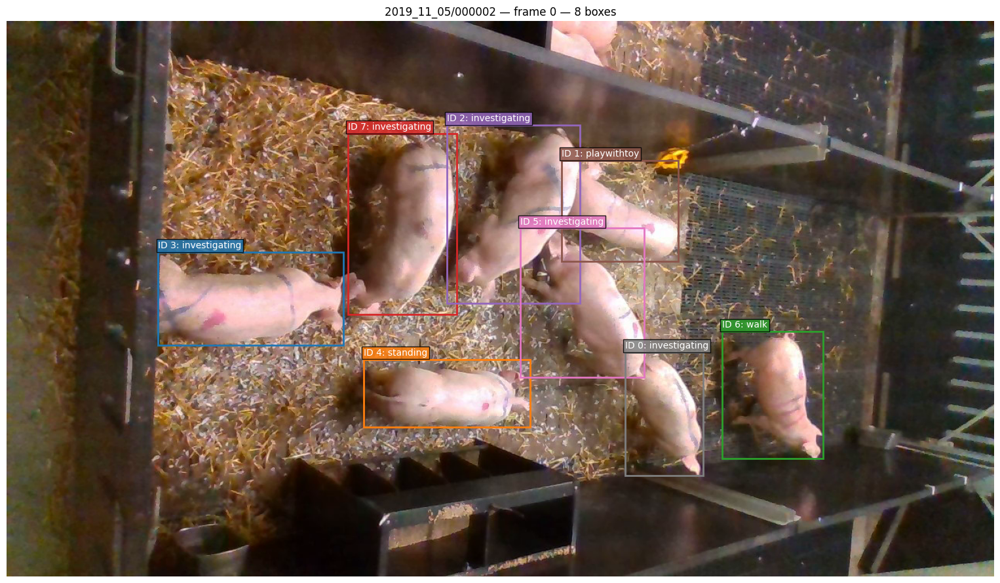

In [3]:
# Box alignment confirmation
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

annotation_path = sorted(
    Path("/kaggle/input").rglob("output.json")
)[0]

with annotation_path.open() as f:
    annotation = json.load(f)

video_path = annotation_path.parent / "color.mp4"

cap = cv2.VideoCapture(str(video_path))
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError(f"Could not read the first frame: {video_path}")

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

shown = 0

for index, pig in enumerate(annotation["objects"]):
    entry = next(
        (e for e in pig["frames"] if e["frameNumber"] == 0),
        None
    )

    if entry is None:
        print(f"No explicit frame-0 entry for pig {pig['id']}")
        continue

    box = entry["bbox"]
    color = plt.get_cmap("tab10")(index % 10)

    ax.add_patch(Rectangle(
        (box["x"], box["y"]),
        box["width"],
        box["height"],
        fill=False,
        edgecolor=color,
        linewidth=2
    ))

    ax.text(
        box["x"],
        max(0, box["y"] - 5),
        f"ID {pig['id']}: {entry['behaviour']}",
        color="white",
        fontsize=10,
        bbox={"facecolor": color, "alpha": 0.85, "pad": 2}
    )
    shown += 1

ax.set_title(
    f"{annotation_path.parent.parent.name}/"
    f"{annotation_path.parent.name} — frame 0 — {shown} boxes"
)
ax.axis("off")
plt.tight_layout()
plt.show()

Labels are organized by pig track, with frame references, boxes, and behaviors

## Inventory all 12 clips
Read video properties and collected labels

In [4]:
from pathlib import Path
import json
import cv2
import pandas as pd

root = Path("/kaggle/input")
rows = []

for annotation_path in sorted(root.rglob("output.json")):
    clip_dir = annotation_path.parent

    with annotation_path.open() as f:
        annotation = json.load(f)

    cap = cv2.VideoCapture(str(clip_dir / "color.mp4"))
    opened = cap.isOpened()

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    tracks = annotation.get("objects", [])
    entries = [
        entry
        for track in tracks
        for entry in track.get("frames", [])
    ]

    behaviors = sorted({
        str(entry["behaviour"])
        for entry in entries
        if entry.get("behaviour") is not None
    })

    frame_numbers = [
        entry["frameNumber"]
        for entry in entries
        if "frameNumber" in entry
    ]

    rows.append({
        "clip_id": f"{clip_dir.parent.name}/{clip_dir.name}",
        "video_opens": opened,
        "fps": round(fps, 3),
        "video_frames": frame_count,
        "duration_seconds": round(frame_count / fps, 2) if fps > 0 else None,
        "resolution": f"{width}x{height}",
        "pig_tracks": len(tracks),
        "stored_entries": len(entries),
        "min_annotation_frame": min(frame_numbers) if frame_numbers else None,
        "max_annotation_frame": max(frame_numbers) if frame_numbers else None,
        "behaviors": ", ".join(behaviors)
    })

inventory = pd.DataFrame(rows)

display(inventory)

all_behaviors = sorted({
    label
    for row in rows
    for label in row["behaviors"].split(", ")
    if label
})

print("\nUnique behavior labels:")
for label in all_behaviors:
    print("-", label)

output_path = Path("/kaggle/working/video_inventory.csv")
inventory.to_csv(output_path, index=False)

,clip_id,video_opens,fps,video_frames,duration_seconds,resolution,pig_tracks,stored_entries,min_annotation_frame,max_annotation_frame,behaviors
0,2019_11_05/000002,True,30.0,1800,60.0,1280x720,8,3586,0,599,"drink, eat, fight, investigating, jumpontopof,..."
1,2019_11_05/000009,True,30.0,1800,60.0,1280x720,8,1361,0,598,"drink, eat, investigating, playwithtoy, run, s..."
2,2019_11_11/000016,True,30.0,1800,60.0,1280x720,8,577,0,599,"drink, eat, investigating, lying, nose-to-nose..."
3,2019_11_11/000028,True,30.0,1800,60.0,1280x720,8,440,0,599,"drink, investigating, lying, sitting, sleep, s..."
4,2019_11_11/000036,True,30.0,1800,60.0,1280x720,8,699,0,599,"drink, eat, fight, investigating, lying, nose-..."
5,2019_11_15/000033,True,30.0,1800,60.0,1280x720,8,979,0,599,"drink, investigating, lying, playwithtoy, sitt..."
6,2019_11_22/000010,True,30.0,1800,60.0,1280x720,8,913,0,599,"chase, fight, investigating, lying, run, sitti..."
7,2019_11_28/000113,True,30.0,1800,60.0,1280x720,8,1815,0,599,"drink, eat, fight, investigating, lying, nose-..."
8,2019_12_02/000005,True,30.0,1800,60.0,1280x720,8,231,0,599,"drink, eat, investigating, lying, sleep, stand..."
9,2019_12_02/000208,True,30.0,1800,60.0,1280x720,8,1474,0,599,"drink, eat, fight, investigating, lying, run, ..."



Unique behavior labels:
- chase
- drink
- eat
- fight
- investigating
- jumpontopof
- lying
- nose-poke-elsewhere
- nose-to-nose
- other
- playwithtoy
- run
- sitting
- sleep
- standing
- walk


12 RGB clips, eight tracks per clip, and 16 behavior labels

## Check Timestamps

Compared capture timestamps with video metadata

In [5]:

times_path = sorted(root.rglob("times.txt"))[0]

with times_path.open() as f:
    lines = [line.strip() for line in f if line.strip()]

print("Clip:", times_path.parent)
print("Non-empty lines:", len(lines))

print("\nFirst 5 lines:")
for line in lines[:5]:
    print(repr(line))

print("\nLast 5 lines:")
for line in lines[-5:]:
    print(repr(line))

Clip: /kaggle/input/datasets/jackbyte/edinburgh-pig-behaviour-annotated/2019_11_05/000002
Non-empty lines: 1800

First 5 lines:
'2019-11-05T12:41:50.022620'
'2019-11-05T12:41:50.178297'
'2019-11-05T12:41:50.338143'
'2019-11-05T12:41:50.492478'
'2019-11-05T12:41:50.646259'

Last 5 lines:
'2019-11-05T12:46:47.127234'
'2019-11-05T12:46:47.292584'
'2019-11-05T12:46:47.458211'
'2019-11-05T12:46:47.623607'
'2019-11-05T12:46:47.789421'


On tryging to resolve the 30fps playback rate, we found the clips represent roughly a 5 minutes of capture, despite playing in one minute

## Audit Annotation Structure

Checked frame indices, boxes, and labels
Goal: Find malformed records before converting them into training data

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/kaggle/input")
rows = []

for times_path in sorted(root.rglob("times.txt")):
    with times_path.open() as f:
        lines = [line.strip() for line in f if line.strip()]

    timestamps = pd.DatetimeIndex(
        pd.to_datetime(lines, errors="raise")
    )

    gaps = np.diff(timestamps.asi8) / 1e9
    elapsed = (timestamps[-1] - timestamps[0]).total_seconds()

    rows.append({
        "clip_id": (
            f"{times_path.parent.parent.name}/"
            f"{times_path.parent.name}"
        ),
        "timestamp_count": len(timestamps),
        "elapsed_seconds": round(elapsed, 3),
        "average_capture_fps": (
            round((len(timestamps) - 1) / elapsed, 3)
            if elapsed > 0 else None
        ),
        "median_gap_ms": round(np.median(gaps) * 1000, 2),
        "min_gap_ms": round(gaps.min() * 1000, 2),
        "max_gap_ms": round(gaps.max() * 1000, 2),
        "duplicate_timestamps": int((gaps == 0).sum()),
        "backward_timestamps": int((gaps < 0).sum())
    })

timing_audit = pd.DataFrame(rows)
display(timing_audit)

timing_audit.to_csv(
    "/kaggle/working/timing_audit.csv",
    index=False
)

,clip_id,timestamp_count,elapsed_seconds,average_capture_fps,median_gap_ms,min_gap_ms,max_gap_ms,duplicate_timestamps,backward_timestamps
0,2019_11_05/000002,1800,297.767,6.042,165.56,150.72,187.23,0,0
1,2019_11_05/000009,1800,297.793,6.041,165.59,150.20,237.85,0,0
2,2019_11_11/000016,1800,304.223,5.913,166.17,154.88,184.77,0,0
3,2019_11_11/000028,1800,298.763,6.021,165.83,155.36,186.53,0,0
4,2019_11_11/000036,1800,297.952,6.038,165.66,154.83,177.85,0,0
5,2019_11_15/000033,1800,297.787,6.041,165.60,156.90,184.13,0,0
6,2019_11_22/000010,1800,297.787,6.041,165.56,154.79,260.18,0,0
7,2019_11_28/000113,1800,297.787,6.041,165.58,153.53,198.90,0,0
8,2019_12_02/000005,1800,297.801,6.041,165.59,152.67,178.76,0,0
9,2019_12_02/000208,1800,297.776,6.041,165.58,153.64,256.45,0,0


All stored records passed the structural checks

In [7]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from numbers import Real

root = Path("/kaggle/input")
rows = []

for annotation_path in sorted(root.rglob("output.json")):
    with annotation_path.open() as f:
        annotation = json.load(f)

    clip_dir = annotation_path.parent
    clip_id = f"{clip_dir.parent.name}/{clip_dir.name}"

    for track in annotation.get("objects", []):
        entries = track.get("frames", [])
        indices = [e.get("frameNumber") for e in entries]

        valid_indices = [
            i for i in indices
            if isinstance(i, int) and not isinstance(i, bool)
        ]

        gaps = np.diff(valid_indices)

        invalid_boxes = 0
        outside_image = 0

        for entry in entries:
            box = entry.get("bbox")

            if not isinstance(box, dict):
                invalid_boxes += 1
                continue

            values = [
                box.get(key)
                for key in ("x", "y", "width", "height")
            ]

            if not all(
                isinstance(v, Real)
                and not isinstance(v, bool)
                and np.isfinite(v)
                for v in values
            ):
                invalid_boxes += 1
                continue

            x, y, width, height = values

            if width <= 0 or height <= 0:
                invalid_boxes += 1
            elif (
                x < 0 or y < 0
                or x + width > 1280
                or y + height > 720
            ):
                outside_image += 1

        rows.append({
            "clip_id": clip_id,
            "pig_id": track.get("id"),
            "stored_entries": len(entries),
            "first_index": min(valid_indices) if valid_indices else None,
            "last_index": max(valid_indices) if valid_indices else None,
            "missing_index_0": 0 not in valid_indices,
            "invalid_frame_indices": len(indices) - len(valid_indices),
            "out_of_range_indices": sum(
                i < 0 or i > 599 for i in valid_indices
            ),
            "duplicate_indices": (
                len(valid_indices) - len(set(valid_indices))
            ),
            "backward_steps": int((gaps < 0).sum()),
            "missing_behavior": sum(
                not isinstance(e.get("behaviour"), str)
                or not e["behaviour"].strip()
                for e in entries
            ),
            "invalid_boxes": invalid_boxes,
            "boxes_outside_image": outside_image
        })

annotation_audit = pd.DataFrame(rows)

issue_columns = [
    "invalid_frame_indices",
    "out_of_range_indices",
    "duplicate_indices",
    "backward_steps",
    "missing_behavior",
    "invalid_boxes",
    "boxes_outside_image"
]

review_mask = (
    annotation_audit[issue_columns].gt(0).any(axis=1)
    | annotation_audit["missing_index_0"]
    | annotation_audit["last_index"].ne(599)
)

print("Total pig tracks:", len(annotation_audit))
print("\nIssue totals:")
print(annotation_audit[issue_columns].sum())

print(
    "\nTracks without an annotation at index 0:",
    annotation_audit["missing_index_0"].sum()
)

print("\nFinal stored index distribution:")
print(
    annotation_audit["last_index"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nTracks requiring review:")
display(annotation_audit.loc[review_mask])

annotation_audit.to_csv(
    "/kaggle/working/annotation_audit.csv",
    index=False
)

Total pig tracks: 96

Issue totals:
invalid_frame_indices    0
out_of_range_indices     0
duplicate_indices        0
backward_steps           0
missing_behavior         0
invalid_boxes            0
boxes_outside_image      0
dtype: int64

Tracks without an annotation at index 0: 0

Final stored index distribution:
last_index
258     1
288     1
348     1
450     4
536     1
567     1
573     1
583     1
584     1
586     1
587     2
592     1
594     1
596     2
597     4
598     8
599    65
Name: count, dtype: int64

Tracks requiring review:


,clip_id,pig_id,stored_entries,first_index,last_index,missing_index_0,invalid_frame_indices,out_of_range_indices,duplicate_indices,backward_steps,missing_behavior,invalid_boxes,boxes_outside_image
2,2019_11_05/000002,6,365,0,596,False,0,0,0,0,0,0,0
4,2019_11_05/000002,2,306,0,587,False,0,0,0,0,0,0,0
8,2019_11_05/000009,0,202,0,598,False,0,0,0,0,0,0,0
9,2019_11_05/000009,7,157,0,592,False,0,0,0,0,0,0,0
10,2019_11_05/000009,1,168,0,598,False,0,0,0,0,0,0,0
11,2019_11_05/000009,4,130,0,594,False,0,0,0,0,0,0,0
12,2019_11_05/000009,2,150,0,598,False,0,0,0,0,0,0,0
13,2019_11_05/000009,5,205,0,598,False,0,0,0,0,0,0,0
14,2019_11_05/000009,6,161,0,596,False,0,0,0,0,0,0,0
15,2019_11_05/000009,3,188,0,598,False,0,0,0,0,0,0,0


## Endpoint Inspection

Complete stored track:
{
  "frames": [
    {
      "frameNumber": 0,
      "bbox": {
        "x": 870,
        "y": 184,
        "width": 153,
        "height": 126
      },
      "isGroundTruth": true,
      "visible": true,
      "behaviour": "sleep"
    },
    {
      "frameNumber": 258,
      "bbox": {
        "x": 872,
        "y": 191,
        "width": 158,
        "height": 112
      },
      "isGroundTruth": true,
      "visible": true,
      "behaviour": "sleep"
    }
  ],
  "id": "0"
}


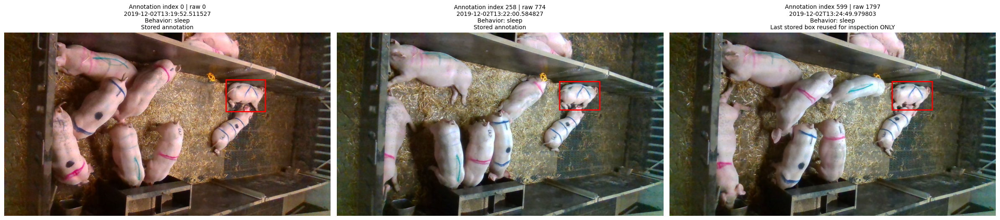

In [8]:
from pathlib import Path
import json
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

root = Path("/kaggle/input")

annotation_path = next(
    p for p in root.rglob("output.json")
    if p.parent.name == "000005"
    and p.parent.parent.name == "2019_12_02"
)

with annotation_path.open() as f:
    annotation = json.load(f)

track = next(
    obj for obj in annotation["objects"]
    if str(obj["id"]) == "0"
)

entries = sorted(
    track["frames"],
    key=lambda entry: entry["frameNumber"]
)

print("Complete stored track:")
print(json.dumps(track, indent=2))

with (annotation_path.parent / "times.txt").open() as f:
    timestamps = [line.strip() for line in f if line.strip()]

checks = [
    (
        entry["frameNumber"],
        entry,
        "Stored annotation"
    )
    for entry in entries
]

if entries[-1]["frameNumber"] < 599:
    checks.append((
        599,
        entries[-1],
        "Last stored box reused for inspection ONLY"
    ))

cap = cv2.VideoCapture(
    str(annotation_path.parent / "color.mp4")
)

fig, axes = plt.subplots(
    1, len(checks),
    figsize=(8 * len(checks), 6),
    squeeze=False
)

for ax, (annotation_index, entry, note) in zip(
    axes[0], checks
):
    raw_index = annotation_index * 3

    cap.set(cv2.CAP_PROP_POS_FRAMES, raw_index)
    ok, frame = cap.read()

    if not ok:
        ax.set_title(f"Could not read raw frame {raw_index}")
        ax.axis("off")
        continue

    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    box = entry["bbox"]
    ax.add_patch(Rectangle(
        (box["x"], box["y"]),
        box["width"],
        box["height"],
        fill=False,
        edgecolor="red",
        linewidth=2
    ))

    ax.set_title(
        f"Annotation index {annotation_index} | raw {raw_index}\n"
        f"{timestamps[raw_index]}\n"
        f"Behavior: {entry['behaviour']}\n"
        f"{note}",
        fontsize=10
    )
    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()

## Reconstruction

In [9]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

root = Path("/kaggle/input")
rows = []

for annotation_path in sorted(root.rglob("output.json")):
    clip_dir = annotation_path.parent
    clip_id = f"{clip_dir.parent.name}/{clip_dir.name}"

    with annotation_path.open() as f:
        annotation = json.load(f)

    with (clip_dir / "times.txt").open() as f:
        timestamps = pd.DatetimeIndex(pd.to_datetime([
            line.strip() for line in f if line.strip()
        ]))

    for track in annotation["objects"]:
        entries = sorted(
            track["frames"],
            key=lambda entry: entry["frameNumber"]
        )

        stored_indices = np.array([
            entry["frameNumber"] for entry in entries
        ])

        target_indices = np.arange(600)

        previous = np.searchsorted(
            stored_indices, target_indices, side="right"
        ) - 1

        if (previous < 0).any():
            raise ValueError(f"Missing starting label: {clip_id}")

        boxes = {
            key: np.interp(
                target_indices,
                stored_indices,
                [entry["bbox"][key] for entry in entries]
            )
            for key in ("x", "y", "width", "height")
        }

        stored_set = set(stored_indices.tolist())
        last_stored = int(stored_indices[-1])

        for index in target_indices:
            index = int(index)
            raw_index = index * 3

            if index in stored_set:
                source = "stored"
            elif index > last_stored:
                source = "trailing_hold"
            else:
                source = "interpolated_box_forward_label"

            rows.append({
                "clip_id": clip_id,
                "pig_id": str(track["id"]),
                "annotation_index": index,
                "raw_frame_index": raw_index,
                "capture_timestamp": timestamps[raw_index],
                "elapsed_seconds": (
                    timestamps[raw_index] - timestamps[0]
                ).total_seconds(),
                "behavior": entries[int(previous[index])]["behaviour"],
                "x": boxes["x"][index],
                "y": boxes["y"][index],
                "width": boxes["width"][index],
                "height": boxes["height"][index],
                "annotation_source": source
            })

labels = pd.DataFrame(rows)

assert len(labels) == 57600
assert not labels.duplicated(
    ["clip_id", "pig_id", "annotation_index"]
).any()
assert labels.groupby(["clip_id", "pig_id"]).size().eq(600).all()

print("Total reconstructed rows:", len(labels))

print("\nRows by annotation source:")
print(labels["annotation_source"].value_counts())

print("\nRows by behavior:")
print(labels["behavior"].value_counts())

display(labels.head())

labels.to_csv(
    "/kaggle/working/reconstructed_annotations.csv",
    index=False
)

Total reconstructed rows: 57600

Rows by annotation source:
annotation_source
interpolated_box_forward_label    43232
stored                            12646
trailing_hold                      1722
Name: count, dtype: int64

Rows by behavior:
behavior
sleep                  16392
investigating          14296
eat                     7093
standing                6263
lying                   5088
walk                    4306
fight                   1367
drink                    962
nose-to-nose             929
sitting                  484
playwithtoy              213
run                      119
nose-poke-elsewhere       75
other                      6
jumpontopof                6
chase                      1
Name: count, dtype: int64


,clip_id,pig_id,annotation_index,raw_frame_index,capture_timestamp,elapsed_seconds,behavior,x,y,width,height,annotation_source
0,2019_11_05/000002,3,0,0,2019-11-05 12:41:50.022620,0.000000,investigating,196.0,299.0,240.0,121.0,stored
1,2019_11_05/000002,3,1,3,2019-11-05 12:41:50.492478,0.469858,investigating,196.0,290.0,261.0,122.0,stored
2,2019_11_05/000002,3,2,6,2019-11-05 12:41:50.958210,0.935590,investigating,196.0,283.0,251.0,190.0,stored
3,2019_11_05/000002,3,3,9,2019-11-05 12:41:51.419631,1.397011,investigating,196.0,289.0,260.0,153.0,stored
4,2019_11_05/000002,3,4,12,2019-11-05 12:41:51.895200,1.872580,investigating,196.0,289.0,274.0,132.0,stored


## Checking reconstructed annotations

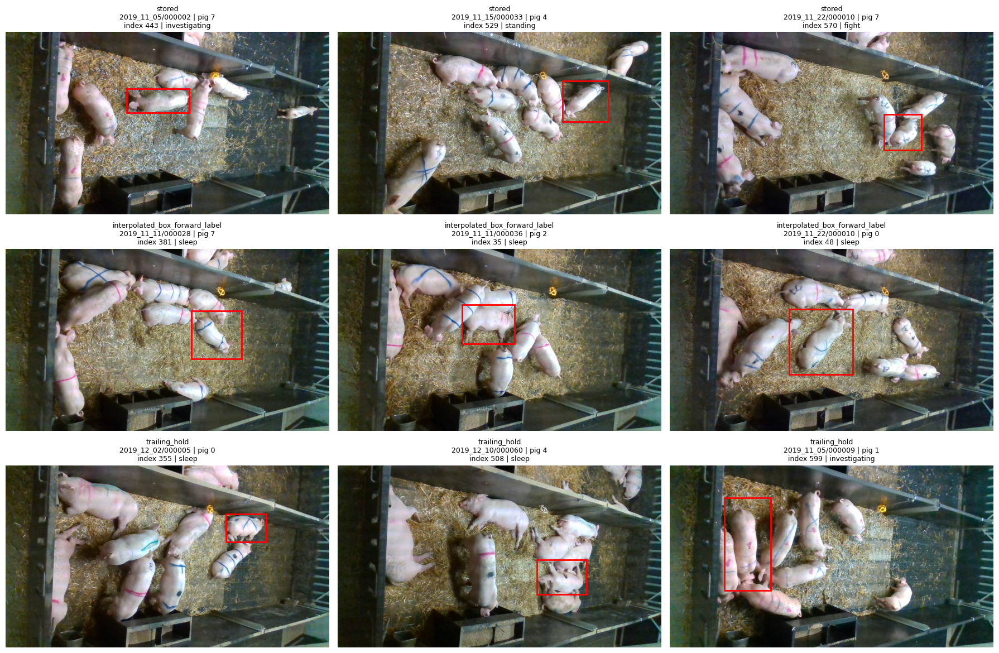

In [10]:
from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

labels = pd.read_csv(
    "/kaggle/working/reconstructed_annotations.csv",
    dtype={"pig_id": str}
)

root = Path("/kaggle/input")

video_paths = {
    f"{p.parent.parent.name}/{p.parent.name}": p
    for p in root.rglob("color.mp4")
}

sources = [
    "stored",
    "interpolated_box_forward_label",
    "trailing_hold"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for row_index, source in enumerate(sources):
    candidates = labels[
        labels["annotation_source"] == source
    ]

    # Prefer different clips within each category.
    examples = (
        candidates.sample(frac=1, random_state=42)
        .drop_duplicates("clip_id")
        .head(3)
    )

    for column_index, ax in enumerate(axes[row_index]):
        if column_index >= len(examples):
            ax.axis("off")
            continue

        example = examples.iloc[column_index]
        video_path = video_paths[example["clip_id"]]

        cap = cv2.VideoCapture(str(video_path))
        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(example["raw_frame_index"])
        )
        ok, frame = cap.read()
        cap.release()

        if not ok:
            ax.set_title("Frame could not be read")
            ax.axis("off")
            continue

        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

        ax.add_patch(Rectangle(
            (example["x"], example["y"]),
            example["width"],
            example["height"],
            fill=False,
            edgecolor="red",
            linewidth=2
        ))

        ax.set_title(
            f"{source}\n"
            f"{example['clip_id']} | pig {example['pig_id']}\n"
            f"index {int(example['annotation_index'])} | "
            f"{example['behavior']}",
            fontsize=9
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

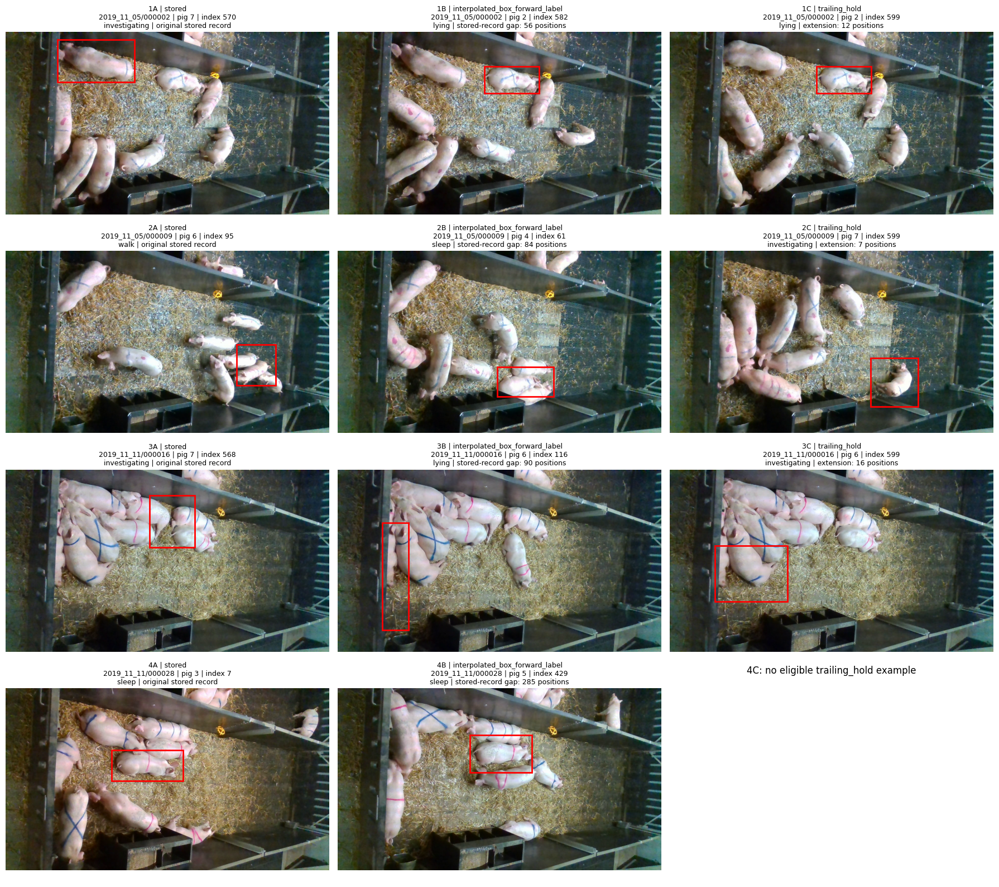

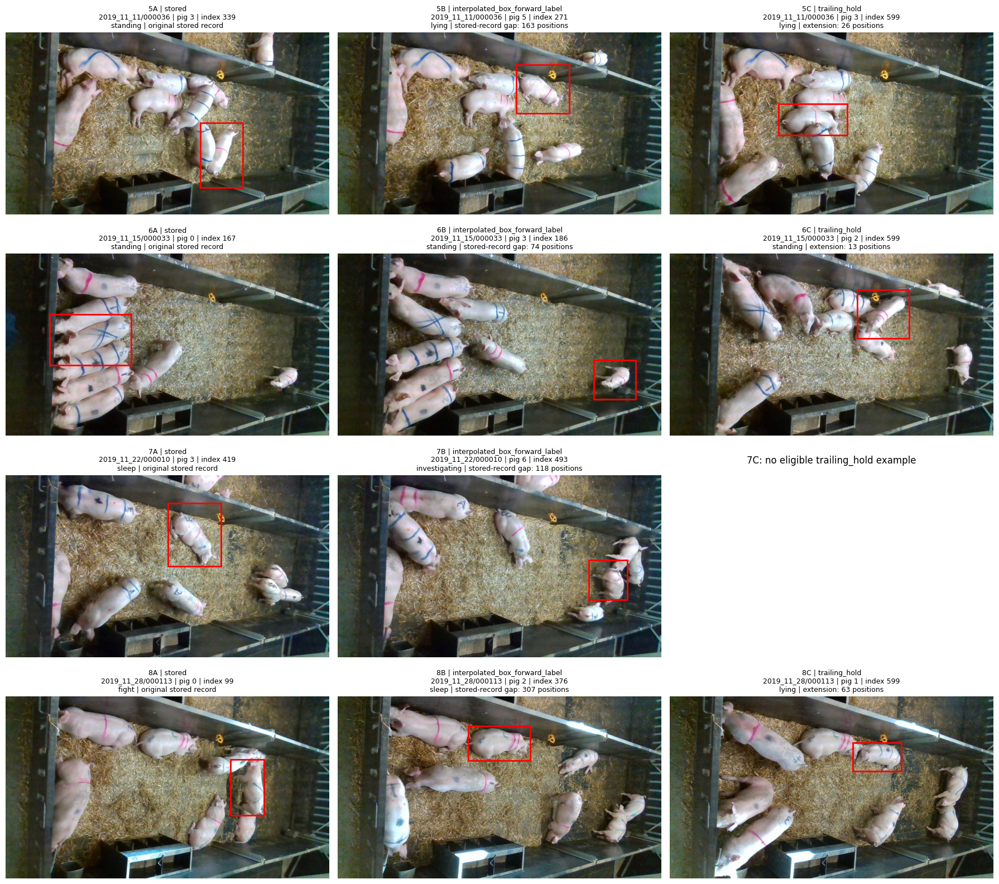

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

labels = pd.read_csv(
    "/kaggle/working/reconstructed_annotations.csv",
    dtype={"pig_id": str}
)

root = Path("/kaggle/input")
sources = [
    "stored",
    "interpolated_box_forward_label",
    "trailing_hold"
]

annotation_paths = {
    f"{p.parent.parent.name}/{p.parent.name}": p
    for p in root.rglob("output.json")
}

previous_path = Path("/kaggle/working/visual_audit_samples.csv")
excluded = set()

if previous_path.exists():
    previous = pd.read_csv(previous_path, dtype={"pig_id": str})
    excluded = set(zip(
        previous["clip_id"],
        previous["pig_id"],
        previous["annotation_index"]
    ))

eligible = labels.loc[
    [
        (clip, pig, index) not in excluded
        for clip, pig, index in zip(
            labels["clip_id"],
            labels["pig_id"],
            labels["annotation_index"]
        )
    ]
].copy()

stored_indices = {}

for clip_id, path in annotation_paths.items():
    with path.open() as f:
        annotation = json.load(f)

    for track in annotation["objects"]:
        stored_indices[(clip_id, str(track["id"]))] = np.array(
            sorted(e["frameNumber"] for e in track["frames"])
        )

def interpolation_gap(row):
    indices = stored_indices[(row["clip_id"], row["pig_id"])]
    position = np.searchsorted(
        indices, int(row["annotation_index"]), side="right"
    )
    return int(indices[position] - indices[position - 1])

selected = []
clip_ids = sorted(labels["clip_id"].unique())

for clip_id in clip_ids:
    for source in sources:
        candidates = eligible[
            (eligible["clip_id"] == clip_id)
            & (eligible["annotation_source"] == source)
        ].copy()

        if candidates.empty:
            continue

        if source == "interpolated_box_forward_label":
            candidates["gap"] = candidates.apply(
                interpolation_gap, axis=1
            )
            hardest = candidates[
                candidates["gap"] == candidates["gap"].max()
            ]
            chosen = hardest.sample(1, random_state=73).iloc[0]
            detail = f"stored-record gap: {int(chosen['gap'])} positions"

        elif source == "trailing_hold":
            candidates["extension"] = candidates.apply(
                lambda r: int(r["annotation_index"])
                - int(stored_indices[
                    (r["clip_id"], r["pig_id"])
                ][-1]),
                axis=1
            )
            chosen = candidates.sort_values(
                "extension", ascending=False
            ).iloc[0]
            detail = f"extension: {int(chosen['extension'])} positions"

        else:
            chosen = candidates.sample(1, random_state=73).iloc[0]
            detail = "original stored record"

        selected.append({
            **chosen[labels.columns].to_dict(),
            "audit_detail": detail
        })

samples = pd.DataFrame(selected)

for start in range(0, len(clip_ids), 4):
    batch = clip_ids[start:start + 4]
    fig, axes = plt.subplots(
        len(batch), 3,
        figsize=(18, 4 * len(batch)),
        squeeze=False
    )

    for row_index, clip_id in enumerate(batch):
        video_path = annotation_paths[clip_id].parent / "color.mp4"
        cap = cv2.VideoCapture(str(video_path))

        for column_index, source in enumerate(sources):
            ax = axes[row_index, column_index]
            match = samples[
                (samples["clip_id"] == clip_id)
                & (samples["annotation_source"] == source)
            ]

            panel = f"{start + row_index + 1}{chr(65 + column_index)}"

            if match.empty:
                ax.set_title(f"{panel}: no eligible {source} example")
                ax.axis("off")
                continue

            example = match.iloc[0]
            cap.set(
                cv2.CAP_PROP_POS_FRAMES,
                int(example["raw_frame_index"])
            )
            ok, frame = cap.read()

            if not ok:
                ax.set_title(f"{panel}: frame read failed")
                ax.axis("off")
                continue

            ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            ax.add_patch(Rectangle(
                (example["x"], example["y"]),
                example["width"],
                example["height"],
                fill=False,
                edgecolor="red",
                linewidth=2
            ))

            ax.set_title(
                f"{panel} | {source}\n"
                f"{clip_id} | pig {example['pig_id']} | "
                f"index {int(example['annotation_index'])}\n"
                f"{example['behavior']} | {example['audit_detail']}",
                fontsize=9
            )
            ax.axis("off")

        cap.release()

    plt.tight_layout()
    plt.show()

samples.to_csv(
    "/kaggle/working/expanded_visual_audit_samples.csv",
    index=False
)

The reconstruction does not hold well across the files thus, it would need better resolve for it to be usable thus we'll leave it here and we can come back later to review

## Count behaviors by clip and date

In [16]:
labels = pd.read_csv(
    "/kaggle/working/reconstructed_annotations.csv",
    dtype={"pig_id": str}
)

labels["recording_date"] = labels["clip_id"].str.split("/").str[0]

behavior_by_clip = pd.crosstab(
    labels["behavior"],
    labels["clip_id"]
)

behavior_by_date = pd.crosstab(
    labels["behavior"],
    labels["recording_date"]
)

summary = (
    labels.groupby("behavior")
    .agg(
        total_pig_frame_rows=("annotation_index", "size"),
        clips_present=("clip_id", "nunique"),
        dates_present=("recording_date", "nunique")
    )
)

trailing_counts = (
    labels.loc[
        labels["annotation_source"] == "trailing_hold"
    ]
    .groupby("behavior")
    .size()
)

summary["trailing_hold_rows"] = (
    trailing_counts.reindex(summary.index, fill_value=0)
)

summary["trailing_hold_percent"] = (
    100 * summary["trailing_hold_rows"]
    / summary["total_pig_frame_rows"]
).round(2)

summary["largest_clip_share_percent"] = (
    100 * behavior_by_clip.max(axis=1)
    / summary["total_pig_frame_rows"]
).round(2)

summary = summary.sort_values(
    "total_pig_frame_rows",
    ascending=False
)

behavior_by_clip = behavior_by_clip.reindex(summary.index)
behavior_by_date = behavior_by_date.reindex(summary.index)

print("Behavior coverage summary:")
display(summary)

print("\nBehavior counts by clip:")
display(behavior_by_clip)

print("\nBehavior counts by recording date:")
display(behavior_by_date)

summary.to_csv(
    "/kaggle/working/behavior_coverage_summary.csv"
)
behavior_by_clip.to_csv(
    "/kaggle/working/behavior_by_clip.csv"
)
behavior_by_date.to_csv(
    "/kaggle/working/behavior_by_date.csv"
)

Behavior coverage summary:


,total_pig_frame_rows,clips_present,dates_present,trailing_hold_rows,trailing_hold_percent,largest_clip_share_percent
behavior,,,,,,
sleep,16392,10,7,1543,9.41,25.62
investigating,14296,11,7,55,0.38,21.22
eat,7093,9,5,1,0.01,28.11
standing,6263,12,7,15,0.24,41.45
lying,5088,10,7,106,2.08,37.01
walk,4306,12,7,1,0.02,23.15
fight,1367,5,5,1,0.07,46.53
drink,962,10,6,0,0.00,19.23
nose-to-nose,929,4,3,0,0.00,53.61



Behavior counts by clip:


clip_id,2019_11_05/000002,2019_11_05/000009,2019_11_11/000016,2019_11_11/000028,2019_11_11/000036,2019_11_15/000033,2019_11_22/000010,2019_11_28/000113,2019_12_02/000005,2019_12_02/000208,2019_12_10/000060,2019_12_10/000078
behavior,,,,,,,,,,,,
sleep,0,255,30,2823,1344,851,1458,764,2434,0,4200,2233
investigating,1752,3034,589,1114,2052,392,1782,753,685,1567,0,576
eat,1,84,1534,0,306,0,0,70,1444,1994,460,1200
standing,739,463,36,372,60,2596,434,425,66,463,101,508
lying,396,0,1883,61,815,18,3,1715,31,135,31,0
walk,997,864,55,275,164,621,483,296,70,326,4,151
fight,15,0,0,0,13,0,590,636,0,113,0,0
drink,141,51,150,17,30,123,0,63,70,185,0,132
nose-to-nose,409,0,498,0,4,0,0,18,0,0,0,0



Behavior counts by recording date:


recording_date,2019_11_05,2019_11_11,2019_11_15,2019_11_22,2019_11_28,2019_12_02,2019_12_10
behavior,,,,,,,
sleep,255,4197,851,1458,764,2434,6433
investigating,4786,3755,392,1782,753,2252,576
eat,85,1840,0,0,70,3438,1660
standing,1202,468,2596,434,425,529,609
lying,396,2759,18,3,1715,166,31
walk,1861,494,621,483,296,396,155
fight,15,13,0,590,636,113,0
drink,192,197,123,0,63,255,132
nose-to-nose,409,502,0,0,18,0,0


## Selection aspects: Trailing hold, reconstruction and stored

In [19]:
# from pathlib import Path
# import pandas as pd

# output = Path("/kaggle/working")

# labels = pd.read_csv(
#     output / "annotations_with_provisional_splits.csv",
#     dtype={"pig_id": str}
# )

# accepted_sources = {"stored", "trailing_hold"}

# expected_sources = {
#     "stored",
#     "trailing_hold",
#     "interpolated_box_forward_label"
# }

# assert set(labels["annotation_source"].unique()) <= expected_sources

# labels["accepted_for_initial_use"] = (
#     labels["annotation_source"].isin(accepted_sources)
# )

# labels["acceptance_reason"] = labels["annotation_source"].map({
#     "stored": "retained_original_record",
#     "trailing_hold": "retained_under_endpoint_policy",
#     "interpolated_box_forward_label": (
#         "deferred_pending_reconstruction_review"
#     )
# })

# accepted = labels.loc[
#     labels["accepted_for_initial_use"]
# ].copy()

# accepted["recording_date"] = (
#     accepted["clip_id"].str.split("/").str[0]
# )

# assert len(accepted) == 14368
# assert len(labels) - len(accepted) == 43232

# print("Acceptance summary:")
# display(
#     labels.groupby(
#         ["annotation_source", "accepted_for_initial_use"]
#     ).size().rename("rows").reset_index()
# )

# coverage = (
#     accepted.groupby("behavior")
#     .agg(
#         accepted_rows=("annotation_index", "size"),
#         clips_present=("clip_id", "nunique"),
#         dates_present=("recording_date", "nunique")
#     )
# )

# original_counts = labels.groupby("behavior").size()

# coverage["previous_rows"] = original_counts
# coverage["retained_percent"] = (
#     100 * coverage["accepted_rows"] / coverage["previous_rows"]
# ).round(2)

# coverage = coverage.sort_values(
#     "accepted_rows", ascending=False
# )

# by_date = pd.crosstab(
#     accepted["behavior"],
#     accepted["recording_date"]
# ).reindex(index=coverage.index, fill_value=0)

# by_clip = pd.crosstab(
#     accepted["behavior"],
#     accepted["clip_id"]
# ).reindex(index=coverage.index, fill_value=0)

# by_split = pd.crosstab(
#     accepted["behavior"],
#     accepted["split"]
# ).reindex(
#     index=coverage.index,
#     columns=["train", "validation", "test"],
#     fill_value=0
# )

# core_classes = [
#     "sleep", "investigating", "eat", "standing",
#     "lying", "walk", "drink"
# ]

# baseline_counts = by_split.reindex(
#     core_classes, fill_value=0
# )

# print("\nAccepted behavior coverage:")
# display(coverage)

# print("\nAccepted counts by recording date:")
# display(by_date)

# print("\nAccepted counts in the provisional seven-class split:")
# display(baseline_counts)

# print("\nMissing baseline class–partition combinations:")
# missing = baseline_counts.eq(0).stack()
# missing = missing[missing]

# if missing.empty:
#     print("None")
# else:
#     print(missing.index.tolist())

# labels.to_csv(
#     output / "annotations_with_acceptance_flags.csv",
#     index=False
# )

# accepted.to_csv(
#     output / "accepted_annotations_provisional.csv",
#     index=False
# )

# coverage.to_csv(output / "accepted_behavior_coverage.csv")
# by_date.to_csv(output / "accepted_behavior_by_date.csv")
# by_clip.to_csv(output / "accepted_behavior_by_clip.csv")
# by_split.to_csv(output / "accepted_behavior_by_split.csv")

In [18]:
from itertools import permutations
import pandas as pd

labels = pd.read_csv(
    "/kaggle/working/reconstructed_annotations.csv",
    dtype={"pig_id": str}
)

labels["recording_date"] = labels["clip_id"].str.split("/").str[0]

core_classes = [
    "sleep", "investigating", "eat", "standing",
    "lying", "walk", "drink"
]

additional_classes = ["fight", "sitting", "nose-to-nose"]
dates = sorted(labels["recording_date"].unique())

date_counts = pd.crosstab(
    labels["behavior"],
    labels["recording_date"]
)

candidates = []
coverage_tables = {}

for candidate_id, (validation_date, test_date) in enumerate(
    permutations(dates, 2), start=1
):
    training_dates = [
        date for date in dates
        if date not in {validation_date, test_date}
    ]

    counts = pd.DataFrame({
        "train": date_counts[training_dates].sum(axis=1),
        "validation": date_counts[validation_date],
        "test": date_counts[test_date]
    }).reindex(core_classes + additional_classes, fill_value=0)

    core = counts.loc[core_classes]

    candidates.append({
        "candidate_id": candidate_id,
        "validation_date": validation_date,
        "test_date": test_date,
        "training_dates": ", ".join(training_dates),
        "missing_core_class_partition_pairs": int(
            core.eq(0).sum().sum()
        ),
        "minimum_core_eval_rows": int(
            core[["validation", "test"]].min().min()
        ),
        "minimum_core_training_rows": int(
            core["train"].min()
        ),
        "train_clips": labels.loc[
            labels["recording_date"].isin(training_dates),
            "clip_id"
        ].nunique(),
        "validation_clips": labels.loc[
            labels["recording_date"].eq(validation_date),
            "clip_id"
        ].nunique(),
        "test_clips": labels.loc[
            labels["recording_date"].eq(test_date),
            "clip_id"
        ].nunique()
    })

    coverage_tables[candidate_id] = counts

ranking = pd.DataFrame(candidates).sort_values(
    [
        "missing_core_class_partition_pairs",
        "minimum_core_eval_rows",
        "minimum_core_training_rows",
        "candidate_id"
    ],
    ascending=[True, False, False, True]
).reset_index(drop=True)

print("Top 6 candidate assignments:")
display(ranking.head(6))

# Reversing validation and test produces the same coverage score.
# Show three different held-out date pairs rather than duplicates.
shown_pairs = set()
selected_ids = []

for _, candidate in ranking.iterrows():
    pair = tuple(sorted([
        candidate["validation_date"],
        candidate["test_date"]
    ]))

    if pair in shown_pairs:
        continue

    shown_pairs.add(pair)
    candidate_id = int(candidate["candidate_id"])
    selected_ids.append(candidate_id)

    print(
        f"\nCandidate {candidate_id}\n"
        f"Validation: {candidate['validation_date']}\n"
        f"Test: {candidate['test_date']}\n"
        f"Training: {candidate['training_dates']}"
    )

    display(coverage_tables[candidate_id])

    if len(selected_ids) == 3:
        break

ranking.to_csv(
    "/kaggle/working/candidate_split_ranking.csv",
    index=False
)

pd.concat(
    {
        candidate_id: coverage_tables[candidate_id]
        for candidate_id in selected_ids
    },
    names=["candidate_id", "behavior"]
).to_csv(
    "/kaggle/working/candidate_split_class_counts.csv"
)

Top 6 candidate assignments:


,candidate_id,validation_date,test_date,training_dates,missing_core_class_partition_pairs,minimum_core_eval_rows,minimum_core_training_rows,train_clips,validation_clips,test_clips
0,11,2019_11_11,2019_12_02,"2019_11_05, 2019_11_15, 2019_11_22, 2019_11_28...",0,166,510,7,3,2
1,32,2019_12_02,2019_11_11,"2019_11_05, 2019_11_15, 2019_11_22, 2019_11_28...",0,166,510,7,2,3
2,1,2019_11_05,2019_11_11,"2019_11_15, 2019_11_22, 2019_11_28, 2019_12_02...",0,85,573,7,2,3
3,7,2019_11_11,2019_11_05,"2019_11_15, 2019_11_22, 2019_11_28, 2019_12_02...",0,85,573,7,3,2
4,5,2019_11_05,2019_12_02,"2019_11_11, 2019_11_15, 2019_11_22, 2019_11_28...",0,85,515,8,2,2
5,31,2019_12_02,2019_11_05,"2019_11_11, 2019_11_15, 2019_11_22, 2019_11_28...",0,85,515,8,2,2



Candidate 11
Validation: 2019_11_11
Test: 2019_12_02
Training: 2019_11_05, 2019_11_15, 2019_11_22, 2019_11_28, 2019_12_10


,train,validation,test
behavior,,,
sleep,9761,4197,2434
investigating,8289,3755,2252
eat,1815,1840,3438
standing,5266,468,529
lying,2163,2759,166
walk,3416,494,396
drink,510,197,255
fight,1241,13,113
sitting,321,163,0



Candidate 1
Validation: 2019_11_05
Test: 2019_11_11
Training: 2019_11_15, 2019_11_22, 2019_11_28, 2019_12_02, 2019_12_10


,train,validation,test
behavior,,,
sleep,11940,255,4197
investigating,5755,4786,3755
eat,5168,85,1840
standing,4593,1202,468
lying,1933,396,2759
walk,1951,1861,494
drink,573,192,197
fight,1339,15,13
sitting,228,93,163



Candidate 5
Validation: 2019_11_05
Test: 2019_12_02
Training: 2019_11_11, 2019_11_15, 2019_11_22, 2019_11_28, 2019_12_10


,train,validation,test
behavior,,,
sleep,13703,255,2434
investigating,7258,4786,2252
eat,3570,85,3438
standing,4532,1202,529
lying,4526,396,166
walk,2049,1861,396
drink,515,192,255
fight,1239,15,113
sitting,391,93,0


## Data Split

In [20]:
from pathlib import Path
import json
import pandas as pd

labels = pd.read_csv(
    "/kaggle/working/reconstructed_annotations.csv",
    dtype={"pig_id": str}
)

baseline_classes = [
    "sleep",
    "investigating",
    "eat",
    "standing",
    "lying",
    "walk",
    "drink"
]

split_dates = {
    "train": [
        "2019_11_05",
        "2019_11_15",
        "2019_11_22",
        "2019_11_28",
        "2019_12_10"
    ],
    "validation": ["2019_11_11"],
    "test": ["2019_12_02"]
}

date_to_split = {
    date: split
    for split, dates in split_dates.items()
    for date in dates
}

labels["recording_date"] = (
    labels["clip_id"].str.split("/").str[0]
)
labels["split"] = labels["recording_date"].map(date_to_split)
labels["baseline_class"] = labels["behavior"].isin(
    baseline_classes
)

assert labels["split"].notna().all()
assert labels.groupby("recording_date")["split"].nunique().eq(1).all()
assert labels.groupby("clip_id")["split"].nunique().eq(1).all()

baseline_counts = pd.crosstab(
    labels.loc[labels["baseline_class"], "behavior"],
    labels.loc[labels["baseline_class"], "split"]
).reindex(
    index=baseline_classes,
    columns=["train", "validation", "test"],
    fill_value=0
)

assert baseline_counts.gt(0).all().all()

print("Baseline class counts:")
display(baseline_counts)

print("\nPartition summary:")
display(
    labels.groupby("split").agg(
        recording_dates=("recording_date", "nunique"),
        clips=("clip_id", "nunique"),
        all_label_rows=("behavior", "size"),
        baseline_rows=("baseline_class", "sum")
    ).reindex(["train", "validation", "test"])
)

output = Path("/kaggle/working")

labels.to_csv(
    output / "annotations_with_provisional_splits.csv",
    index=False
)

with (output / "provisional_split_config.json").open("w") as f:
    json.dump({
        "candidate_id": 11,
        "status": "provisional",
        "grouping": "recording_date",
        "split_dates": split_dates,
        "baseline_classes": baseline_classes,
        "bounding_box_review": "unresolved",
        "trailing_hold_policy": "retained_and_flagged"
    }, f, indent=2)

Baseline class counts:


split,train,validation,test
behavior,,,
sleep,9761,4197,2434
investigating,8289,3755,2252
eat,1815,1840,3438
standing,5266,468,529
lying,2163,2759,166
walk,3416,494,396
drink,510,197,255



Partition summary:


,recording_dates,clips,all_label_rows,baseline_rows
split,,,,
train,5,7,33600,31220
validation,1,3,14400,13710
test,1,2,9600,9470


## Retain Stored and trailing hold

In [21]:
import numpy as np

output = Path("/kaggle/working")
output.mkdir(parents=True, exist_ok=True)

required_columns = [
    "clip_id", "pig_id", "annotation_index", "raw_frame_index",
    "x", "y", "width", "height", "behavior",
    "annotation_source", "recording_date", "split",
    "baseline_class"
]

missing = sorted(set(required_columns) - set(labels.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")

labels = labels.copy()

allowed_sources = {
    "stored",
    "interpolated_box_forward_label",
    "trailing_hold"
}

observed_sources = set(labels["annotation_source"].dropna().unique())

if labels["annotation_source"].isna().any():
    raise ValueError("Some rows have a missing annotation_source.")

if not observed_sources.issubset(allowed_sources):
    raise ValueError(
        f"Unexpected annotation sources: {observed_sources - allowed_sources}"
    )

labels["accepted_for_initial_use"] = labels["annotation_source"].isin(
    ["stored", "trailing_hold"]
)

labels["acceptance_reason"] = labels["annotation_source"].map({
    "stored": "retained_original_record",
    "trailing_hold": "retained_under_endpoint_policy",
    "interpolated_box_forward_label":
        "deferred_pending_reconstruction_review"
})

# Stable identifiers for this reconstruction table.
# Run this cell against the original, unchanged reconstruction order.
labels["observation_id"] = [
    f"obs_{i:06d}" for i in range(len(labels))
]

accepted = labels.loc[
    labels["accepted_for_initial_use"]
].copy()

baseline = accepted.loc[
    accepted["baseline_class"]
].copy()

assert labels["observation_id"].is_unique
assert accepted["annotation_source"].isin(
    ["stored", "trailing_hold"]
).all()
assert baseline["behavior"].isin(baseline_classes).all()

labels.to_csv(
    output / "annotations_with_acceptance_flags.csv",
    index=False
)

accepted.to_csv(
    output / "accepted_annotations_provisional.csv",
    index=False
)

print("Annotation-source counts:")
display(
    labels.groupby(
        ["annotation_source", "accepted_for_initial_use"]
    ).size().rename("rows").reset_index()
)

print(f"All reconstructed observations: {len(labels):,}")
print(f"Accepted observations: {len(accepted):,}")
print(f"Deferred observations: {(~labels['accepted_for_initial_use']).sum():,}")
print(f"Accepted seven-class observations: {len(baseline):,}")

expected_counts = {
    "stored": 12646,
    "interpolated_box_forward_label": 43232,
    "trailing_hold": 1722
}

actual_counts = labels["annotation_source"].value_counts().to_dict()

if actual_counts != expected_counts:
    print(
        "\nWARNING: Counts differ from the previous checkpoint. "
        "Investigate before continuing."
    )

Annotation-source counts:


,annotation_source,accepted_for_initial_use,rows
0,interpolated_box_forward_label,False,43232
1,stored,True,12646
2,trailing_hold,True,1722


All reconstructed observations: 57,600
Accepted observations: 14,368
Deferred observations: 43,232
Accepted seven-class observations: 12,794


## Verify baseline counts and save coverage 

In [22]:
split_order = ["train", "validation", "test"]

baseline_counts = pd.crosstab(
    baseline["behavior"],
    baseline["split"]
).reindex(
    index=baseline_classes,
    columns=split_order
).fillna(0).astype(int)

expected_baseline_counts = pd.DataFrame(
    [
        [979, 159, 935],
        [2984, 705, 569],
        [231, 236, 514],
        [1594, 93, 140],
        [467, 223, 17],
        [2226, 239, 272],
        [134, 29, 48]
    ],
    index=baseline_classes,
    columns=split_order
)

assert baseline_counts.gt(0).all().all(), (
    "At least one baseline class is absent from a partition."
)

assert baseline.groupby("recording_date")["split"].nunique().eq(1).all()
assert baseline.groupby("clip_id")["split"].nunique().eq(1).all()

print("Accepted baseline counts:")
display(baseline_counts)

if not np.array_equal(
    baseline_counts.to_numpy(),
    expected_baseline_counts.to_numpy()
):
    raise ValueError(
        "Baseline counts differ from the previous checkpoint. "
        "Check the reconstruction, source policy, and split before continuing."
    )

coverage = accepted.groupby("behavior").agg(
    accepted_rows=("observation_id", "size"),
    clips=("clip_id", "nunique"),
    dates=("recording_date", "nunique")
).sort_values("accepted_rows", ascending=False)

coverage.to_csv(output / "accepted_behavior_coverage.csv")

for group_column, filename in [
    ("recording_date", "accepted_behavior_by_date.csv"),
    ("clip_id", "accepted_behavior_by_clip.csv"),
    ("split", "accepted_behavior_by_split.csv")
]:
    pd.crosstab(
        accepted["behavior"],
        accepted[group_column]
    ).to_csv(output / filename)

baseline_counts.to_csv(
    output / "accepted_baseline_counts.csv"
)

baseline.to_csv(
    output / "baseline_annotations_provisional.csv",
    index=False
)

print("Partition summary:")
display(
    baseline.groupby("split").agg(
        recording_dates=("recording_date", "nunique"),
        clips=("clip_id", "nunique"),
        observations=("observation_id", "size")
    ).reindex(split_order)
)

Accepted baseline counts:


split,train,validation,test
behavior,,,
sleep,979,159,935
investigating,2984,705,569
eat,231,236,514
standing,1594,93,140
lying,467,223,17
walk,2226,239,272
drink,134,29,48


Partition summary:


,recording_dates,clips,observations
split,,,
train,5,7,8615
validation,1,3,1684
test,1,2,2495


## Locate the RGB videos

In [23]:
import cv2

DATA_ROOT = Path(
    "/kaggle/input/datasets/jackbyte/edinburgh-pig-behaviour-annotated"
)

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root not found: {DATA_ROOT}\n"
        "Check the dataset location in Kaggle's Input panel."
    )

rgb_paths = sorted(DATA_ROOT.rglob("color.mp4"))

if not rgb_paths:
    raise FileNotFoundError("No color.mp4 files were found.")

def clip_parts(value):
    return tuple(str(value).replace("\\", "/").strip("/").split("/"))

video_map = {}

for clip_id in sorted(baseline["clip_id"].unique()):
    parts = clip_parts(clip_id)

    matches = [
        path for path in rgb_paths
        if tuple(path.parent.parts[-len(parts):]) == parts
    ]

    if len(matches) != 1:
        raise ValueError(
            f"{clip_id}: expected one RGB video, found {len(matches)}.\n"
            f"Matches: {matches}"
        )

    video_map[clip_id] = matches[0]

video_mapping = pd.DataFrame([
    {"clip_id": clip_id, "video_path": str(path)}
    for clip_id, path in video_map.items()
])

display(video_mapping)

video_mapping.to_csv(
    output / "baseline_video_mapping.csv",
    index=False
)

,clip_id,video_path
0,2019_11_05/000002,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
1,2019_11_05/000009,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
2,2019_11_11/000016,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
3,2019_11_11/000028,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
4,2019_11_11/000036,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
5,2019_11_15/000033,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
6,2019_11_22/000010,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
7,2019_11_28/000113,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
8,2019_12_02/000005,/kaggle/input/datasets/jackbyte/edinburgh-pig-...
9,2019_12_02/000208,/kaggle/input/datasets/jackbyte/edinburgh-pig-...


## Create review panels before extracting the full dataset

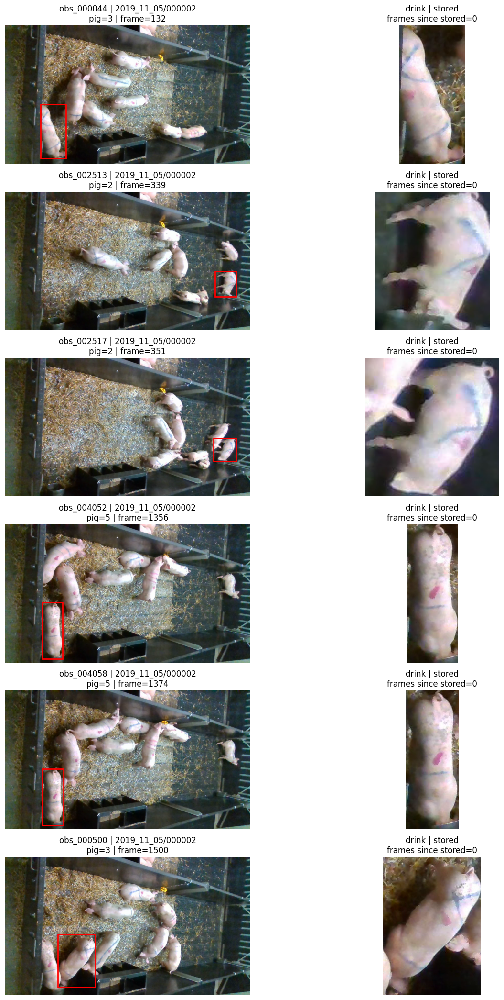

KeyboardInterrupt: 

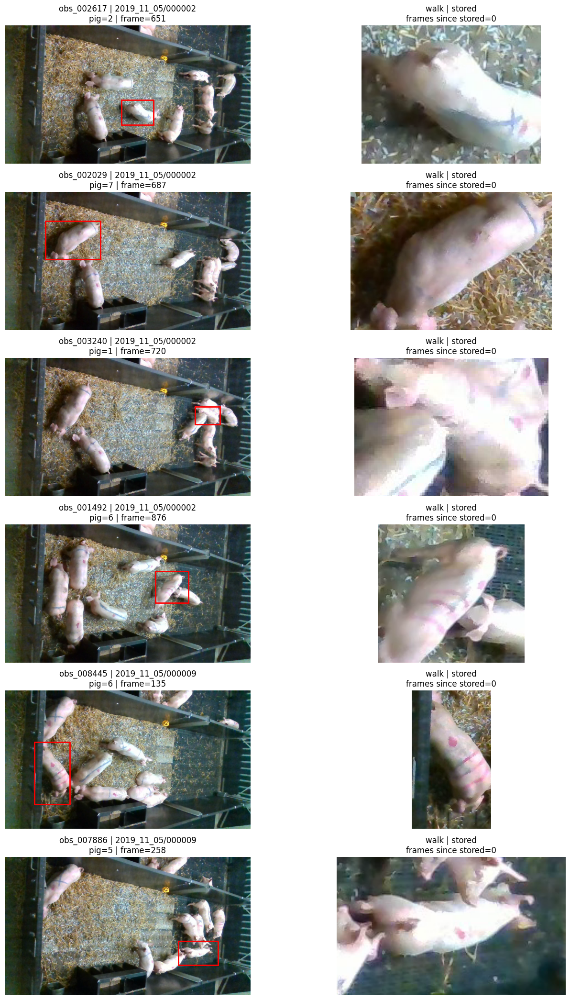

In [24]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

review_dir = output / "baseline_visual_review"
review_dir.mkdir(parents=True, exist_ok=True)

def crop_bounds(row, frame):
    values = np.array(
        [row["x"], row["y"], row["width"], row["height"]],
        dtype=float
    )

    if not np.isfinite(values).all():
        raise ValueError("Non-finite box coordinates.")

    x, y, width, height = values

    if width <= 0 or height <= 0:
        raise ValueError("Non-positive box dimensions.")

    frame_h, frame_w = frame.shape[:2]

    x1 = max(0, min(frame_w, math.floor(x)))
    y1 = max(0, min(frame_h, math.floor(y)))
    x2 = max(0, min(frame_w, math.ceil(x + width)))
    y2 = max(0, min(frame_h, math.ceil(y + height)))

    if x2 <= x1 or y2 <= y1:
        raise ValueError("Box is empty after clipping to the frame.")

    return x1, y1, x2, y2

def read_rgb_frame(clip_id, frame_index):
    frame_index = float(frame_index)

    if (
        not np.isfinite(frame_index)
        or frame_index < 0
        or not frame_index.is_integer()
    ):
        raise ValueError(f"Invalid frame index: {frame_index}")

    cap = cv2.VideoCapture(str(video_map[clip_id]))

    try:
        if not cap.isOpened():
            raise RuntimeError(f"Cannot open video: {clip_id}")

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        ok, frame = cap.read()

        if not ok:
            raise RuntimeError(
                f"Cannot decode {clip_id}, frame {int(frame_index)}"
            )

        return frame
    finally:
        cap.release()

sample_parts = []

for behavior in baseline_classes:
    group = baseline.loc[baseline["behavior"].eq(behavior)]

    initial_parts = []

    for source in ["stored", "trailing_hold"]:
        source_rows = group.loc[group["annotation_source"].eq(source)]
        if len(source_rows):
            initial_parts.append(
                source_rows.sample(
                    n=min(10, len(source_rows)),
                    random_state=42
                )
            )

    chosen = pd.concat(initial_parts)

    remaining = group.loc[~group.index.isin(chosen.index)]
    needed = min(20, len(group)) - len(chosen)

    if needed > 0:
        chosen = pd.concat([
            chosen,
            remaining.sample(n=needed, random_state=42)
        ])

    sample_parts.append(chosen)

review_sample = pd.concat(sample_parts).drop_duplicates("observation_id")

missing_clips = set(baseline["clip_id"]) - set(review_sample["clip_id"])

for clip_id in sorted(missing_clips):
    extra = baseline.loc[
        baseline["clip_id"].eq(clip_id)
    ].sample(n=1, random_state=42)

    review_sample = pd.concat([review_sample, extra])

review_sample = review_sample.sort_values(
    ["behavior", "clip_id", "raw_frame_index"]
).reset_index(drop=True)

# Distance from the most recent stored annotation, in decoded frame positions.
# This is not elapsed time.
stored_lookup = {
    key: np.sort(group["raw_frame_index"].astype(int).unique())
    for key, group in labels.loc[
        labels["annotation_source"].eq("stored")
    ].groupby(["clip_id", "pig_id"])
}

def frames_since_stored(row):
    positions = stored_lookup.get((row["clip_id"], row["pig_id"]))

    if positions is None:
        return np.nan

    prior = positions[positions <= int(row["raw_frame_index"])]

    if len(prior) == 0:
        return np.nan

    return int(row["raw_frame_index"]) - int(prior[-1])

review_sample["frames_since_stored"] = review_sample.apply(
    frames_since_stored, axis=1
)

review_sample["box_status"] = ""
review_sample["label_status"] = ""
review_sample["review_action"] = ""
review_sample["review_note"] = ""

review_sample.to_csv(
    review_dir / "annotation_visual_review.csv",
    index=False
)

page_size = 6

for start in range(0, len(review_sample), page_size):
    page = review_sample.iloc[start:start + page_size]

    fig, axes = plt.subplots(
        len(page), 2,
        figsize=(15, 3.5 * len(page)),
        squeeze=False
    )

    for row_number, (_, row) in enumerate(page.iterrows()):
        frame = read_rgb_frame(
            row["clip_id"], row["raw_frame_index"]
        )

        x1, y1, x2, y2 = crop_bounds(row, frame)

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        crop_rgb = frame_rgb[y1:y2, x1:x2]

        axes[row_number, 0].imshow(frame_rgb)
        axes[row_number, 0].add_patch(
            Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="red", linewidth=2
            )
        )

        axes[row_number, 0].set_title(
            f"{row['observation_id']} | {row['clip_id']}\n"
            f"pig={row['pig_id']} | frame={int(row['raw_frame_index'])}"
        )

        axes[row_number, 1].imshow(crop_rgb)
        axes[row_number, 1].set_title(
            f"{row['behavior']} | {row['annotation_source']}\n"
            f"frames since stored={row['frames_since_stored']}"
        )

        for ax in axes[row_number]:
            ax.axis("off")

    fig.tight_layout()

    page_number = start // page_size + 1
    fig.savefig(
        review_dir / f"review_page_{page_number:02d}.png",
        dpi=120,
        bbox_inches="tight"
    )

    if page_number == 1:
        plt.show()

    plt.close(fig)

print(f"Review observations: {len(review_sample)}")
print(f"Review pages: {math.ceil(len(review_sample) / page_size)}")
print(f"Review outputs: {review_dir}")

## Baseline Crop extraction

In [27]:
from pathlib import Path
import pandas as pd

review_path = Path(
    "/kaggle/working/baseline_visual_review/"
    "annotation_visual_review.csv"
)

review = pd.read_csv(
    review_path,
    dtype={"pig_id": str},
    keep_default_na=False
)

review_rules = {
    "box_status": {"usable", "incorrect", "uncertain"},
    "label_status": {
        "plausible",
        "questionable",
        "cannot_assess_from_still"
    },
    "review_action": {"retain", "exclude", "inspect_context"}
}

for column, allowed in review_rules.items():
    review[column] = (
        review[column]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    invalid = ~review[column].isin(allowed)

    print(
        f"{column}: "
        f"{invalid.sum()} incomplete or invalid rows "
        f"out of {len(review)}"
    )

    if invalid.any():
        display(
            review.loc[
                invalid,
                [
                    "observation_id",
                    "behavior",
                    "annotation_source",
                    column
                ]
            ].head(20)
        )

review.to_csv(review_path, index=False)

box_status: 140 incomplete or invalid rows out of 140


,observation_id,behavior,annotation_source,box_status
0,obs_000044,drink,stored,
1,obs_002513,drink,stored,
2,obs_002517,drink,stored,
3,obs_004052,drink,stored,
4,obs_004058,drink,stored,
5,obs_000500,drink,stored,
6,obs_004792,drink,stored,
7,obs_007594,drink,stored,
8,obs_006512,drink,stored,
9,obs_013390,drink,stored,


label_status: 140 incomplete or invalid rows out of 140


,observation_id,behavior,annotation_source,label_status
0,obs_000044,drink,stored,
1,obs_002513,drink,stored,
2,obs_002517,drink,stored,
3,obs_004052,drink,stored,
4,obs_004058,drink,stored,
5,obs_000500,drink,stored,
6,obs_004792,drink,stored,
7,obs_007594,drink,stored,
8,obs_006512,drink,stored,
9,obs_013390,drink,stored,


review_action: 140 incomplete or invalid rows out of 140


,observation_id,behavior,annotation_source,review_action
0,obs_000044,drink,stored,
1,obs_002513,drink,stored,
2,obs_002517,drink,stored,
3,obs_004052,drink,stored,
4,obs_004058,drink,stored,
5,obs_000500,drink,stored,
6,obs_004792,drink,stored,
7,obs_007594,drink,stored,
8,obs_006512,drink,stored,
9,obs_013390,drink,stored,


In [30]:
from pathlib import Path
import json
import math

import cv2
import numpy as np
import pandas as pd


# --------------------------------------------------
# 1. Paths and agreed baseline configuration
# --------------------------------------------------

OUTPUT = Path("/kaggle/working")

DATA_ROOT = Path(
    "/kaggle/input/datasets/jackbyte/edinburgh-pig-behaviour-annotated"
)

ANNOTATIONS_PATH = OUTPUT / "annotations_with_provisional_splits.csv"

CROP_ROOT = OUTPUT / "baseline_crops"
MANIFEST_PATH = OUTPUT / "baseline_crop_manifest.csv"
FAILURES_PATH = OUTPUT / "baseline_crop_failures.csv"

BASELINE_CLASSES = [
    "sleep",
    "investigating",
    "eat",
    "standing",
    "lying",
    "walk",
    "drink"
]

SPLIT_ORDER = ["train", "validation", "test"]

SPLIT_DATES = {
    "train": [
        "2019_11_05",
        "2019_11_15",
        "2019_11_22",
        "2019_11_28",
        "2019_12_10"
    ],
    "validation": ["2019_11_11"],
    "test": ["2019_12_02"]
}

DATE_TO_SPLIT = {
    date: split
    for split, dates in SPLIT_DATES.items()
    for date in dates
}

ACCEPTED_SOURCES = {"stored", "trailing_hold"}

KNOWN_SOURCES = {
    "stored",
    "trailing_hold",
    "interpolated_box_forward_label"
}

OUTPUT.mkdir(parents=True, exist_ok=True)

if not ANNOTATIONS_PATH.is_file():
    raise FileNotFoundError(
        f"Annotation file not found: {ANNOTATIONS_PATH}\n"
        "Run your provisional-split cell first."
    )

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_ROOT}\n"
        "Check the dataset location in Kaggle's Input panel."
    )


# --------------------------------------------------
# 2. Load annotations and validate the existing split
# --------------------------------------------------

labels = pd.read_csv(
    ANNOTATIONS_PATH,
    dtype={
        "clip_id": str,
        "pig_id": str,
        "recording_date": str
    }
)

required_columns = {
    "clip_id",
    "pig_id",
    "annotation_index",
    "raw_frame_index",
    "x",
    "y",
    "width",
    "height",
    "behavior",
    "annotation_source",
    "recording_date",
    "split"
}

missing_columns = required_columns - set(labels.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

if labels[list(required_columns)].isna().any().any():
    raise ValueError(
        "Required annotation fields contain missing values."
    )

unknown_sources = (
    set(labels["annotation_source"].unique()) - KNOWN_SOURCES
)

if unknown_sources:
    raise ValueError(
        f"Unexpected annotation sources: {sorted(unknown_sources)}"
    )

expected_splits = labels["recording_date"].map(DATE_TO_SPLIT)

if expected_splits.isna().any():
    raise ValueError(
        "Some recording dates are not included in candidate 11."
    )

if not labels["split"].eq(expected_splits).all():
    raise ValueError(
        "Saved partitions do not match the agreed candidate 11 split."
    )

if not labels.groupby("recording_date")["split"].nunique().eq(1).all():
    raise ValueError("A recording date crosses partitions.")

if not labels.groupby("clip_id")["split"].nunique().eq(1).all():
    raise ValueError("A clip crosses partitions.")

if labels.duplicated(
    ["clip_id", "pig_id", "annotation_index"]
).any():
    raise ValueError(
        "Duplicate clip/pig/annotation-position rows were found."
    )

# Preserve identifiers if already present; otherwise use saved row order.
if "observation_id" not in labels.columns:
    labels["observation_id"] = [
        f"obs_{index:06d}"
        for index in range(len(labels))
    ]

if (
    labels["observation_id"].isna().any()
    or not labels["observation_id"].is_unique
):
    raise ValueError("Observation identifiers must be present and unique.")


# --------------------------------------------------
# 3. Apply the agreed acceptance policy
# --------------------------------------------------

labels["accepted_for_initial_use"] = (
    labels["annotation_source"].isin(ACCEPTED_SOURCES)
)

labels["acceptance_reason"] = labels["annotation_source"].map({
    "stored": "retained_original_record",
    "trailing_hold": "retained_under_endpoint_policy",
    "interpolated_box_forward_label":
        "deferred_pending_reconstruction_review"
})

labels["baseline_class"] = labels["behavior"].isin(BASELINE_CLASSES)

accepted = labels.loc[
    labels["accepted_for_initial_use"]
].copy()

baseline = accepted.loc[
    accepted["baseline_class"]
].copy()

if baseline.empty:
    raise ValueError("No accepted baseline observations were found.")

baseline_counts = pd.crosstab(
    baseline["behavior"],
    baseline["split"]
).reindex(
    index=BASELINE_CLASSES,
    columns=SPLIT_ORDER
).fillna(0).astype(int)

if not baseline_counts.gt(0).all().all():
    raise ValueError(
        "At least one baseline class is missing from a partition."
    )

print("Annotation-source counts:")
display(labels["annotation_source"].value_counts().rename("rows"))

print(f"All reconstructed observations: {len(labels):,}")
print(f"Accepted observations: {len(accepted):,}")
print(f"Seven-class baseline observations: {len(baseline):,}")

print("\nAccepted baseline counts:")
display(baseline_counts)

# Check against the previously agreed data checkpoint.
expected_counts = np.array([
    [979, 159, 935],
    [2984, 705, 569],
    [231, 236, 514],
    [1594, 93, 140],
    [467, 223, 17],
    [2226, 239, 272],
    [134, 29, 48]
])

if (
    len(accepted) != 14368
    or not np.array_equal(
        baseline_counts.to_numpy(),
        expected_counts
    )
):
    raise ValueError(
        "Counts differ from the agreed checkpoint. "
        "Check the input annotations before extracting crops."
    )

labels.to_csv(
    OUTPUT / "annotations_with_acceptance_flags.csv",
    index=False
)

accepted.to_csv(
    OUTPUT / "accepted_annotations_provisional.csv",
    index=False
)

baseline.to_csv(
    OUTPUT / "baseline_annotations_provisional.csv",
    index=False
)


# --------------------------------------------------
# 4. Validate frame indices and box values
# --------------------------------------------------

numeric_columns = [
    "raw_frame_index", "x", "y", "width", "height"
]

for column in numeric_columns:
    baseline[column] = pd.to_numeric(
        base

Annotation-source counts:


annotation_source
interpolated_box_forward_label    43232
stored                            12646
trailing_hold                      1722
Name: rows, dtype: int64

All reconstructed observations: 57,600
Accepted observations: 14,368
Seven-class baseline observations: 12,794

Accepted baseline counts:


split,train,validation,test
behavior,,,
sleep,979,159,935
investigating,2984,705,569
eat,231,236,514
standing,1594,93,140
lying,467,223,17
walk,2226,239,272
drink,134,29,48


2019_11_05/000002: wrote 3,026 of 3,026 required crops
2019_11_05/000009: wrote 1,361 of 1,361 required crops
2019_11_11/000016: wrote 557 of 557 required crops
2019_11_11/000028: wrote 420 of 420 required crops
2019_11_11/000036: wrote 707 of 707 required crops
2019_11_15/000033: wrote 960 of 960 required crops
2019_11_22/000010: wrote 752 of 752 required crops
2019_11_28/000113: wrote 1,339 of 1,339 required crops
2019_12_02/000005: wrote 1,134 of 1,134 required crops
2019_12_02/000208: wrote 1,361 of 1,361 required crops
2019_12_10/000060: wrote 790 of 790 required crops
2019_12_10/000078: wrote 387 of 387 required crops

Extraction completed successfully.
Total crops: 12,794
Boxes clipped to image boundaries: 0


split,train,validation,test
behavior,,,
sleep,979,159,935
investigating,2984,705,569
eat,231,236,514
standing,1594,93,140
lying,467,223,17
walk,2226,239,272
drink,134,29,48



Ready for Part 6 of the training code. No manual-review CSV is required.


# Setup Trainig

In [31]:
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training will run on CPU and may be slow.")

output = Path("/kaggle/working")
training_dir = output / "baseline_training"
training_dir.mkdir(parents=True, exist_ok=True)

classes = [
    "sleep",
    "investigating",
    "eat",
    "standing",
    "lying",
    "walk",
    "drink"
]

class_to_idx = {
    name: index for index, name in enumerate(classes)
}

manifest_path = output / "baseline_crop_manifest.csv"

if not manifest_path.exists():
    raise FileNotFoundError(
        "Complete crop preparation first: "
        "baseline_crop_manifest.csv was not found."
    )

manifest = pd.read_csv(
    manifest_path,
    dtype={"pig_id": str}
)

required = {
    "observation_id", "crop_path", "behavior",
    "split", "recording_date", "clip_id",
    "annotation_source"
}

missing = required - set(manifest.columns)

if missing:
    raise ValueError(f"Missing manifest columns: {sorted(missing)}")

assert manifest["observation_id"].is_unique
assert manifest["behavior"].isin(classes).all()
assert manifest["split"].isin(
    ["train", "validation", "test"]
).all()

assert manifest["annotation_source"].isin(
    ["stored", "trailing_hold"]
).all()

assert manifest.groupby(
    "recording_date"
)["split"].nunique().eq(1).all()

assert manifest.groupby(
    "clip_id"
)["split"].nunique().eq(1).all()

missing_paths = [
    path for path in manifest["crop_path"]
    if not Path(path).is_file()
]

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} crops are missing. "
        f"First example: {missing_paths[0]}"
    )

train_df = manifest.loc[
    manifest["split"].eq("train")
].reset_index(drop=True)

val_df = manifest.loc[
    manifest["split"].eq("validation")
].reset_index(drop=True)

test_df = manifest.loc[
    manifest["split"].eq("test")
].reset_index(drop=True)

for name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    if set(frame["behavior"]) != set(classes):
        raise ValueError(f"{name} does not contain all seven classes.")

display(
    pd.crosstab(
        manifest["behavior"], manifest["split"]
    ).reindex(
        index=classes,
        columns=["train", "validation", "test"]
    )
)

Device: cpu


split,train,validation,test
behavior,,,
sleep,979,159,935
investigating,2984,705,569
eat,231,236,514
standing,1594,93,140
lying,467,223,17
walk,2226,239,272
drink,134,29,48


## Setup Data Loaders

In [32]:
class PadToSquare:
    def __call__(self, image):
        width, height = image.size
        side = max(width, height)

        canvas = Image.new(
            "RGB", (side, side), color=(124, 116, 104)
        )

        left = (side - width) // 2
        top = (side - height) // 2

        canvas.paste(image, (left, top))
        return canvas


IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

# Fixed normalization associated with the pretrained image model.
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])


class PigCropDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["crop_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        target = class_to_idx[row["behavior"]]

        return image, target


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_dataset = PigCropDataset(train_df, train_transform)
val_dataset = PigCropDataset(val_df, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda",
    worker_init_fn=seed_worker,
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda",
    worker_init_fn=seed_worker
)

images, targets = next(iter(train_loader))

print("Image batch shape:", tuple(images.shape))
print("Target batch shape:", tuple(targets.shape))

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(images).all()

Image batch shape: (32, 3, 224, 224)
Target batch shape: (32,)


##  Initialize the model and training configuration

In [34]:
weights = models.MobileNet_V3_Small_Weights.DEFAULT

try:
    model = models.mobilenet_v3_small(weights=weights)
except Exception as exc:
    raise RuntimeError(
        "Could not load pretrained MobileNetV3-Small weights. "
        "Enable Kaggle Internet or provide cached weights, then retry. "
        "Training has not started."
    ) from exc

input_features = model.classifier[-1].in_features

model.classifier[-1] = nn.Linear(
    input_features, len(classes)
)

model = model.to(device)

train_class_counts = train_df["behavior"].value_counts().reindex(
    classes
)

class_weights = (
    len(train_df) /
    (len(classes) * train_class_counts.to_numpy(dtype=float))
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

train_criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# Unweighted validation loss for a straightforward descriptive measure.
val_criterion = nn.CrossEntropyLoss()

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 15
PATIENCE = 4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

training_config = {
    "model": "mobilenet_v3_small",
    "pretrained_weights": str(weights),
    "classes": classes,
    "class_to_idx": class_to_idx,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "selection_metric": "validation_macro_f1",
    "training_loss": "weighted_cross_entropy",
    "validation_loss": "unweighted_cross_entropy",
    "class_weights": {
        name: float(value)
        for name, value in zip(classes, class_weights)
    },
    "split_candidate": 11,
    "input_type": "single_annotated_pig_crop",
    "resize_policy": "pad_to_square_then_resize",
    "normalization_mean": MEAN,
    "normalization_std": STD,
    "train_augmentation": {
        "horizontal_flip_probability": 0.5,
        "color_jitter": {
            "brightness": 0.1,
            "contrast": 0.1,
            "saturation": 0.1
        }
    },
    "train_observations": len(train_df),
    "validation_observations": len(val_df),
    "test_observations": len(test_df),
    "torch_version": str(torch.__version__)
}

with (training_dir / "training_config.json").open("w") as f:
    json.dump(training_config, f, indent=2)

display(pd.DataFrame({
    "behavior": classes,
    "training_observations": train_class_counts.to_numpy(),
    "loss_weight": class_weights
}))

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 98.1MB/s]


,behavior,training_observations,loss_weight
0,sleep,979,1.257114
1,investigating,2984,0.412438
2,eat,231,5.327767
3,standing,1594,0.772092
4,lying,467,2.635362
5,walk,2226,0.552882
6,drink,134,9.184435


Trainable parameters: 1,525,031


## Baseline Training

In [35]:
from tqdm.auto import tqdm


def run_epoch(loader, training):
    model.train(training)

    running_loss = 0.0
    seen = 0
    all_targets = []
    all_predictions = []

    criterion = train_criterion if training else val_criterion

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    )

    for images, targets in progress:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = targets.size(0)

        running_loss += loss.item() * batch_size
        seen += batch_size

        predictions = logits.argmax(dim=1)

        all_targets.extend(targets.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())

    precision, recall, macro_f1, _ = (
        precision_recall_fscore_support(
            all_targets,
            all_predictions,
            labels=list(range(len(classes))),
            average="macro",
            zero_division=0
        )
    )

    metrics = {
        # Training loss is an average of weighted batch-loss values.
        "loss": running_loss / seen,
        "accuracy": accuracy_score(
            all_targets, all_predictions
        ),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1
    }

    return metrics, all_targets, all_predictions


best_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0
history = []

checkpoint_path = training_dir / "best_baseline.pt"

if checkpoint_path.exists():
    raise FileExistsError(
        "A baseline checkpoint already exists. "
        "Use a new training_dir for a new experiment "
        "instead of accidentally overwriting this run."
    )

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()

    train_metrics, _, _ = run_epoch(
        train_loader, training=True
    )

    val_metrics, _, _ = run_epoch(
        val_loader, training=False
    )

    epoch_seconds = time.perf_counter() - epoch_start

    record = {
        "epoch": epoch,
        "epoch_seconds": epoch_seconds,
        **{
            f"train_{key}": value
            for key, value in train_metrics.items()
        },
        **{
            f"validation_{key}": value
            for key, value in val_metrics.items()
        }
    }

    history.append(record)

    pd.DataFrame(history).to_csv(
        training_dir / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"train F1={train_metrics['macro_f1']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} | "
        f"val F1={val_metrics['macro_f1']:.4f} | "
        f"{epoch_seconds:.1f}s"
    )

    if val_metrics["macro_f1"] > best_f1:
        best_f1 = float(val_metrics["macro_f1"])
        best_epoch = epoch
        epochs_without_improvement = 0

        cpu_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        torch.save({
            "model_state_dict": cpu_state,
            "epoch": epoch,
            "validation_macro_f1": best_f1,
            "config": training_config
        }, checkpoint_path)

        print("  Saved new best checkpoint.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

total_training_seconds = time.perf_counter() - training_start

run_summary = {
    "best_epoch": best_epoch,
    "best_validation_macro_f1": best_f1,
    "epochs_completed": len(history),
    "total_training_seconds": total_training_seconds,
    "device": str(device),
    "test_evaluated": False
}

with (training_dir / "run_summary.json").open("w") as f:
    json.dump(run_summary, f, indent=2)

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_f1:.4f}")
print(f"Total training time: {total_training_seconds / 60:.1f} minutes")

Training:   0%|          | 0/270 [00:00<?, ?it/s]

Validation:   0%|          | 0/53 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78ea31cb5e40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x78ea31cb5e40>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        if w.is_alive():self._shutdown_workers()
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
assert self._parent_pid == os.getpid(), 'can only test a child process'    
if w.is_alive():
AssertionError:   File "/usr/lib/python3.13/multiprocessing/pro

Epoch 01/15 | train loss=1.1359 | train F1=0.4375 | val loss=1.7985 | val F1=0.2507 | 239.5s
  Saved new best checkpoint.


Training:   0%|          | 0/270 [00:00<?, ?it/s]

Validation:   0%|          | 0/53 [00:00<?, ?it/s]

... (14 outputs left out)

Epoch 06/15 | train loss=0.3470 | train F1=0.8382 | val loss=2.3739 | val F1=0.2361 | 211.2s


Training:   0%|          | 0/270 [00:00<?, ?it/s]

Validation:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 07/15 | train loss=0.3199 | train F1=0.8564 | val loss=2.3364 | val F1=0.2296 | 211.0s
Early stopping.

Training finished.
Best epoch: 3
Best validation macro-F1: 0.2860
Total training time: 26.3 minutes


## Validation

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78ea31cb5e40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78ea31cb5e40>    
Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()
if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

Validation:   0%|          | 0/53 [00:00<?, ?it/s]

Best-checkpoint validation results:


,precision,recall,f1-score,support
sleep,0.2361,0.6667,0.3487,159.000
investigating,0.5813,0.3447,0.4328,705.000
eat,0.5694,0.1737,0.2662,236.000
standing,0.1318,0.5484,0.2125,93.000
lying,0.2797,0.1794,0.2186,223.000
walk,0.4000,0.1925,0.2599,239.000
drink,0.1700,0.5862,0.2636,29.000
accuracy,0.3230,0.3230,0.3230,0.323
macro avg,0.3383,0.3845,0.2860,1684.000
weighted avg,0.4495,0.3230,0.3335,1684.000


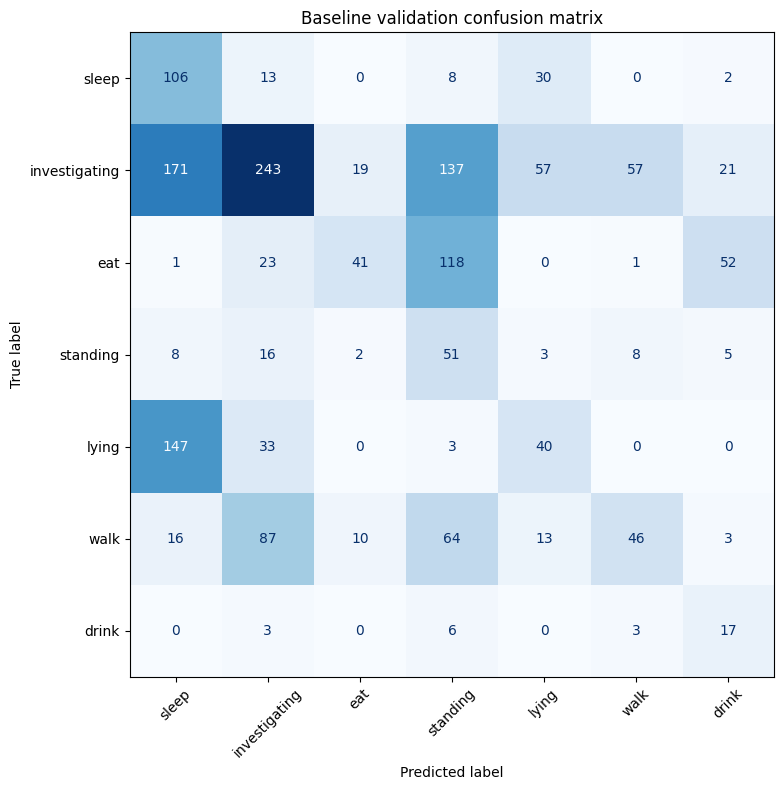

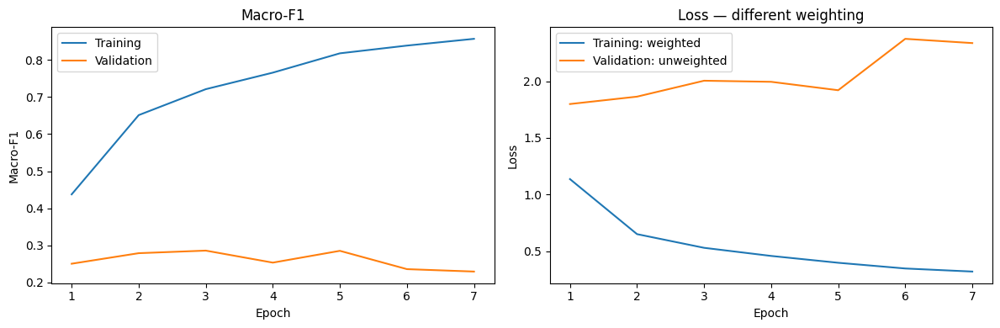

Checkpoint size, MiB: 5.94
Test partition remains unevaluated.


In [36]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

val_metrics, val_targets, val_predictions = run_epoch(
    val_loader, training=False
)

report = classification_report(
    val_targets,
    val_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    training_dir / "validation_classification_report.csv"
)

print("Best-checkpoint validation results:")
display(report_df.round(4))

prediction_table = val_df.copy()

prediction_table["predicted_behavior"] = [
    classes[index] for index in val_predictions
]

prediction_table["correct"] = (
    prediction_table["behavior"]
    == prediction_table["predicted_behavior"]
)

prediction_table.to_csv(
    training_dir / "validation_predictions.csv",
    index=False
)

matrix = confusion_matrix(
    val_targets,
    val_predictions,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("Baseline validation confusion matrix")
fig.tight_layout()

fig.savefig(
    training_dir / "validation_confusion_matrix.png",
    dpi=150
)

plt.show()
plt.close(fig)

history_df = pd.read_csv(
    training_dir / "training_history.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Training"
)

axes[0].plot(
    history_df["epoch"],
    history_df["validation_macro_f1"],
    label="Validation"
)

axes[0].set_title("Macro-F1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Macro-F1")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training: weighted"
)

axes[1].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation: unweighted"
)

axes[1].set_title("Loss — different weighting")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

fig.tight_layout()

fig.savefig(
    training_dir / "training_curves.png",
    dpi=150
)

plt.show()
plt.close(fig)

print("Checkpoint size, MiB:",
      round(checkpoint_path.stat().st_size / (1024 ** 2), 2))

print("Test partition remains unevaluated.")